In [1]:
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import plotly.express as px

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
5.5 Principal Component Analysis
</div></font>

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Main Idea Behind PCA</b>
</div></font> 

Suppose we have a dataset with many features. This dataset can be viewed as a collection of points in a high-dimensional space, where the dimension of the space is equal to the number of features. In dimensionality reduction, we want to reduce the dimension of this space by creating new coordinates that are linear combinations of the original ones. But how do we decide which new coordinates to use?

Some features may be highly correlated. This means that they contain similar information about the data, so we may not need to keep both of them separately. Instead, we can combine them, for example by creating a new feature that is a linear combination of the two. In this way, we can reduce the dimensionality of the dataset while retaining much of the variation in the original data.

Some features may have very little variation across the dataset. Such features may contribute relatively little to distinguishing the data points from one another. On the other hand, directions in which the data vary substantially may capture important patterns in the dataset.

As these examples suggest, to reduce the dimensionality effectively, we need to examine the variances and covariances of the features. We want to focus on directions of high variation while removing correlations between the new variables. This is the idea behind **Principal Component Analysis** (**PCA**). 

The goal of PCA is to find a change of variables that produces new, uncorrelated variables, ordered by decreasing variance. Equivalently, PCA finds a new set of orthonormal basis vectors, with the variance of the projected data decreasing from one direction to the next. These directions are called **principal components**. The first principal component points in the direction along which the projected data have the largest variance. Each subsequent principal component points in a direction of maximum remaining variance, subject to being orthogonal to the preceding components.

Let's look at this visually. Suppose we have a dataset with two features, $x_1$ and $x_2$, shown in the figure below (left). The first principal component, $PC \text{ } 1$, is the direction along which the data vary the most, and the second principal component, $PC \text{ } 2$, is the direction of maximum remaining variance subject to being orthogonal to $PC \text{ } 1$. PCA finds these directions and transforms the data into the new coordinate system defined by these principal components, as shown on the right. Notice that there is no correlation between $PC \text{ } 1$ and $PC \text{ } 2$. As one of them increases or decreases, there is no particular tendency for the other to increase or decrease.


<center> <img src="data:image/png;base64,  ...
 " width="80%"> </center>

Notice that if we wanted to find a one-dimensional subspace onto which we could project our data while preserving as much of its variation as possible, $PC \text{ } 1$ would be the natural choice. Therefore, if we reduce the dimensionality of our data from two dimensions to one, we would project the data onto the $PC \text{ } 1$ axis.

To go from the left image to the right, we need to do three things:

<strong>1. Center the data.</strong> This part is simple: the center of the data is its mean, so we subtract the mean from every data point. This is usually done first.<br>

<strong>2. Find the principal component directions.</strong> This can be done in two equivalent ways: we can apply SVD to the centered data matrix, or we can diagonalize its covariance matrix. In either case, we obtain the principal component directions as orthonormal vectors.<br>

<strong>3. Transform the centered data to the new coordinate system.</strong> We rotate the centered data (and possibly flip it) so that the principal component directions become the new coordinate axes. Since the principal component directions are orthogonal, this transformation is a rotation and/or reflection. Therefore, its matrix is orthogonal. Explicitly transforming the data into principal-component coordinates is not necessary if our goal is only to identify the principal directions, but it is necessary if we want to express the data in the new coordinate system.

First, let's review some statistics needed for PCA.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Sample Covariance Matrix</b>
</div></font> 

Datasets are usually organized so that each row represents a data point and each column represents a feature. However, for computational purposes, it is often more convenient to orient the data so that each column represents a data point. We can do this by transposing the data matrix. 

Let $X = \begin{bmatrix} {\bf x}_1 & \cdots & {\bf x}_N \end{bmatrix}$ be a $p \times N$ matrix representing a dataset with $N$ data points and $p$ features. So, each column is a data point. Then the **sample mean** of the data is 
$${\bf m}=\frac{1}{N}({\bf x}_1 + \cdots + {\bf x}_N)$$

To center the data, we subtract the mean from each data point: ${\bf x}_i - {\bf m}$ for each $i=1, \cdots , N$. We can easily achieve this using broadcasting: $$\hat{X}=X-{\bf m}$$

The matrix $\hat{X}$ is a $p \times N$ matrix whose columns are the deviations of the data points from their mean. Each feature in $\hat{X}$ has sample mean zero. Such a matrix is said to be in **mean-deviation form**, and the data are said to be **centered**.

The **sample covariance matrix** is the $p \times p$ matrix $S$ defined by $$\require{bbox}\bbox[10px, border: 2px solid blue]{S=\frac{1}{N-1}\hat{X}\hat{X}^T}$$

To understand why this gives the sample covariance matrix, consider the product $\hat{X}\hat{X}^T$. The $i$-th diagonal entry is the dot product of the $i$-th row of $\hat{X}$ with itself. Therefore, it is the sum of the squared deviations of the $i$-th feature from its mean. Dividing by $N-1$ gives the sample variance of that feature. Variance tells us how spread out the values of a feature are.

Similarly, the $(i,j)$-th off-diagonal entry is the dot product of the $i$-th and $j$-th rows of $\hat{X}$. It is therefore the sum of the products of the deviations of the two features from their respective means. Dividing by $N-1$ gives their sample covariance. Covariance measures the linear relationship between two features. A positive covariance indicates that the two features tend to increase together: when one feature has a value above its mean, the other tends to have a value above its mean as well. A negative covariance indicates that they tend to move in opposite directions: when one feature has a value above its mean, the other tends to have a value below its mean. A covariance of zero indicates that the two features are uncorrelated, meaning that there is no linear relationship between the two features. However, they may still have a nonlinear relationship.


Thus, the diagonal entries of $S$ contain the variances of the features, while the off-diagonal entries contain the covariances between pairs of features.


For example, the sample data in the previous figure have the covariance matrix $$S=\begin{bmatrix} 2&3 \\ 3&6\end{bmatrix}$$ This means that the variances of $x_1$ and $x_2$, and their covariance, are given by $$Var(x_1)=2, \quad Var(x_2)=6, \quad \text{and} \quad Cov(x_1,x_2)=3$$
The positive covariance of 3 indicates that the two features have a positive linear relationship: the data tend to extend from the lower-left toward the upper-right, as illustrated by the red line in the figure. The variances indicate that the data have less spread in the $x_1$ direction than in the $x_2$ direction.

<center> <img src="data:image/png;base64,  ...
 " width="30%"> </center>

---
**<font color="red">Example 1</font>**

Suppose you are given the following dataset with 4 data points and 3 features: $${\bf x}_1=\begin{bmatrix} 13 \\ 0 \\1 \end{bmatrix}, \quad {\bf x}_2=\begin{bmatrix} 13 \\ 6 \\7 \end{bmatrix}, \quad {\bf x}_3=\begin{bmatrix} 4 \\ 3 \\10 \end{bmatrix}, \quad \text{and} \quad {\bf x}_4=\begin{bmatrix} 2 \\ 11 \\6\end{bmatrix}$$ Center the data and find the sample covariance matrix.

**Solution.**

To center the data, we first need to find the mean vector:

$${\bf m}=\frac{1}{N}({\bf x}_1+{\bf x}_2+{\bf x}_3+{\bf x}_4)=\frac{1}{4}\left( \begin{bmatrix} 13 \\ 0 \\1\end{bmatrix} + \begin{bmatrix} 13 \\ 6 \\7\end{bmatrix} + \begin{bmatrix}4 \\ 3 \\10\end{bmatrix}+\begin{bmatrix} 2 \\ 11 \\6\end{bmatrix} \right) = \begin{bmatrix} 8 \\ 5 \\6\end{bmatrix}$$

We then subtract the mean from each data point:
$$\hat{\bf x}_1=\begin{bmatrix} 5 \\ -5 \\-5\end{bmatrix}, \quad \hat{\bf x}_2=\begin{bmatrix} 5 \\ 1 \\1\end{bmatrix}, \quad \hat{\bf x}_3=\begin{bmatrix} -4 \\ -2 \\4\end{bmatrix}, \quad \text{and} \quad \hat{\bf x}_4=\begin{bmatrix} -6 \\ 6 \\0\end{bmatrix}$$

Placing the centered data points together as columns gives the centered data matrix: $$\hat{X}=\begin{bmatrix} 5 & 5 & -4 & -6 \\ -5 & 1 & -2 & 6 \\ -5 & 1 & 4 & 0 \end{bmatrix}$$

Finally, the sample covariance matrix is 
$$S=\frac{1}{N-1}\hat{X}\hat{X}^T=\frac{1}{3}\begin{bmatrix} 5 & 5 & -4 & -6 \\ -5 & 1 & -2 & 6 \\ -5 & 1 & 4 & 0 \end{bmatrix}\begin{bmatrix} 5 & -5 &-5 \\ 5 & 1 &1 \\ -4 &-2 &4 \\ -6 & 6 &0\end{bmatrix}=\frac{1}{3}\begin{bmatrix} 102 & -48 & -36  \\ -48 & 66 & 18 \\ -36 & 18& 42 \end{bmatrix}=\begin{bmatrix} 34 &-16 & -12  \\ -16 & 22 &6 \\ -12 & 6 & 14 \end{bmatrix}$$

Hence, the variances are
$$Var(x_1)=34, \quad Var(x_2)=22, \quad \text{and} \quad Var(x_3)=14;$$

and the covariances are

$$Cov(x_1,x_2)=-16, \quad Cov(x_1,x_3)=-12, \quad \text{and} \quad Cov(x_2,x_3)=6$$



######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Finding Principal Components</b>
</div></font> 

For the rest of this chapter, we assume that the data have already been centered, so the data matrix $X$ is already in mean-deviation form.

Recall that for any matrix $A$, both $AA^T$ and $A^TA$ are symmetric and positive semidefinite. Multiplying a positive semidefinite matrix by a positive scalar does not change this property. Therefore, since $N-1>0$, the sample covariance matrix $S$ is symmetric and positive semidefinite. Consequently, $S$ has real, nonnegative eigenvalues and is orthogonally diagonalizable.

We want to find an orthogonal change of variables ${\bf x}=P{\bf y}$ such that the sample covariance matrix of the new variables is diagonal. A diagonal covariance matrix has zeros in all its off-diagonal entries, which means that the new variables have zero covariance with one another. Along the main diagonal, we will have the variances of the new variables. We want these variances to be arranged in descending order, so that the first new variable has the largest variance, the second has the next largest variance, and so on.

Suppose $Y$ is the data matrix in the new coordinate system. Since ${\bf x}=P{\bf y}$, we have ${\bf y}=P^{-1}{\bf x}=P^T{\bf x}$, because $P$ is orthogonal. Therefore, $$Y=P^{-1}X=P^TX$$

Since $X$ is centered, $Y$ is centered as well. If $S$ is the sample covariance matrix for $X$, then the sample covariance matrix for $Y$ is

$$\frac{1}{N-1}YY^T=\frac{1}{N-1}P^TX(P^TX)^T=\frac{1}{N-1}P^TXX^TP=P^T\left(\frac{1}{N-1}XX^T\right)P=P^TSP$$

Since we want $P^TSP$ to be diagonal, we choose the columns of $P$ to be orthonormal eigenvectors of $S$. Then $P^TSP$ is a diagonal matrix whose diagonal entries are the corresponding eigenvalues of $S$. Note that since $S$ is symmetric, orthogonal diagonalization is possible.

Finally, to arrange the variances in descending order, we order the eigenvectors so that their corresponding eigenvalues satisfy $\lambda_1\geq\lambda_2\geq\cdots\geq\lambda_p $.
Thus,
$$
P^TSP=
\begin{bmatrix}
\lambda_1&0&\cdots&0\\
0&\lambda_2&\cdots&0\\
\vdots&\vdots&\ddots&\vdots\\
0&0&\cdots&\lambda_p
\end{bmatrix},
$$
where $\lambda_i$ is the variance of the $i$-th new variable.

The new variables are linear combinations of the original variables, with coefficients given by the corresponding unit eigenvectors. For example, if ${\bf u}_1$ is the eigenvector corresponding to $\lambda_1$ with entries $c_1, \cdots, c_p$, and $x_1, \cdots, x_p$ are the original variables, then the first principal component is given by $$y_1=c_1x_1+ \cdots + c_px_p = {\bf u}_1^T{\bf x}$$

Lastly, we define the **total variance** of the data as the sum of the variances of all the variables. This is the sum of the diagonal entries of $S$, called the **trace** of $S$, and denoted by $tr(S)$. Orthogonal diagonalization does not change the total variance. Therefore, if $D$ is the diagonal matrix containing the eigenvalues $\lambda_1,\cdots, \lambda_p$ of $S$, then 
$$\text{TotalVariance}(x_1, \cdots, x_p)=\text{TotalVariance}(y_1, \cdots, y_p) = tr(D)=\lambda_1 + \cdots +\lambda_p$$

The quotient $$\frac{\lambda_i}{tr(S)}=\frac{\lambda_i}{\lambda_1+ \cdots +\lambda_p}$$ measures the fraction of the total variance explained by the $i$-th principal component $y_i$. 

---

**<font color="red">Example 2</font>**

The data in Example 1 had the sample covariance matrix $$S=\begin{bmatrix} 34 &-16 & -12  \\ -16 & 22 &6 \\ -12 & 6 & 14\end{bmatrix}$$ Find the principal components of the data. Write the new variable determined by the first principal component in terms of the original variables. What is the variance along the first principal component? How much of the total variation is explained by each principal component?

**Solution.**

The eigenvalues of $S$ are $$\lambda_1=50, \quad \lambda_2=12, \quad \text{and} \quad \lambda_3=8$$ with corresponding unit eigenvectors

$${\bf u}_1=\begin{bmatrix} -0.78 \\ 0.52 \\ 0.34 \end{bmatrix}, \quad {\bf u}_2=\begin{bmatrix} -0.32 \\ -0.81 \\ 0.47 \end{bmatrix}, \quad \text{and} \quad {\bf u}_3=\begin{bmatrix} 0.53 \\ 0.27 \\ 0.8 \end{bmatrix}$$

The eigenvector directions define the principal components. The first principal component is approximately $y_1=-0.78x_1+0.52x_2+0.34x_3$.

The variance along the first principal component direction is equal to the largest eigenvalue: $Var(y_1)=\lambda_1=50$.

Finally, the total variance is $\lambda_1+\lambda_2+\lambda_3=50+12+8=70$. Therefore, the fraction of the total variation explained by the first principal component is $50/70 \approx 0.714$. So, the first principal component explains approximately $71.4\%$ of the total variation in the data.

The second principal component explains $12/70 \approx 0.171$ of the total variation, and the third principal component explains $8/70 \approx 0.114$ of the total variation.

---

Notice that the last principal component explains only $11.4\%$ of the total variation, which is small compared with the variation explained by the first two principal components. We may therefore choose to drop this component. In other words, we project our data onto the subspace spanned by the first two principal components. This allows us to reduce the dimensionality of our data from $3$ to $2$ while retaining approximately $88.6\%$ of the total variation.

In real datasets, it is often possible to retain a large proportion of the total variation using only a relatively small number of principal components. However, this depends on the particular dataset. PCA provides the explained-variance fractions that allow us to decide how many components to retain and how much variation we are willing to discard.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>PCA and SVD</b>
</div></font> 

Suppose $X$ is a $p \times N$ data matrix in the mean-deviation form. Let $$A=\frac{1}{\sqrt{N-1}}X^T$$ Then the sample covariance matrix $S$ of $X$ can be written in terms of $A$: $$S=A^TA$$


Recall that if $A=U\Sigma V^T$ is the singular value decomposition of $A$, then the columns of $V$ are the eigenvectors of $A^TA$, and the corresponding eigenvalues are the squares of the singular values. Therefore, the right singular vectors of $A$ give the eigenvectors of $S$ and hence, the principal directions of the data. 

The principal component variables are obtained by projecting the centered data onto these principal directions. Thus, performing PCA is equivalent to performing an SVD of the centered data matrix, up to the scaling factor $\frac{1}{\sqrt{N-1}}$.

Similarly, dimensionality reduction using PCA is equivalent to using a truncated SVD of the centered data matrix: keeping only the first $k$ singular vectors corresponds to keeping the first $k$ principal components.

In practice, PCA is usually computed using an SVD algorithm rather than by first forming the sample covariance matrix and then computing its eigenvalue decomposition. Forming $XX^T$ can reduce numerical accuracy. Direct SVD methods can therefore provide better numerical stability while avoiding the explicit formation of the covariance matrix.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Centering and Standardization of Data</b>
</div></font> 

We often standardize a dataset, which means centering each feature and then scaling it so that its variance is equal to 1. For PCA, however, we do not necessarily perform the second step. So the question is: Should we standardize the data before applying PCA?

The answer is: it depends. 

PCA applied to centered data finds directions of maximum variance. When the data are standardized, PCA instead finds the principal components of the correlation matrix. Standardization gives each feature the same variance, so features measured on different scales contribute more equally to the analysis.

If the data are only centered, features with larger scales can contribute more to the total variance and therefore have a greater influence on the principal components. This is appropriate when the features are measured in the same units and their scales are meaningfully comparable. However, centering sparse matrices (with many zero entries) explicitly can destroy sparsity by replacing zero entries with nonzero values. For this reason, truncated SVD without centering is sometimes preferred for sparse datasets.

If the data are standardized, each feature has variance 1, so each feature contributes equally to the total variance before considering correlations between features. This can prevent features with large numerical scales from dominating the principal components. Standardization is particularly useful when features are measured in different units or have very different magnitudes, such as age measured in years and income measured in dollars.


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>PCA in Python</b>
</div></font> 

Let's load a dataset containing images of handwritten digits.

In [16]:
X, y = load_digits(return_X_y=True)
X.shape, y.shape

((1797, 64), (1797,))

In the previous chapter, we performed truncated SVD using the first $5$ singular values. Now, let's reduce the dimensionality of the data by projecting it onto the first $5$ principal components using `PCA` from `sklearn`. Note that `PCA` automatically centers the data.

In [17]:
n_components = 5
pca = PCA(n_components=n_components)
X_reduced = pca.fit_transform(X)
X_reduced.shape

(1797, 5)

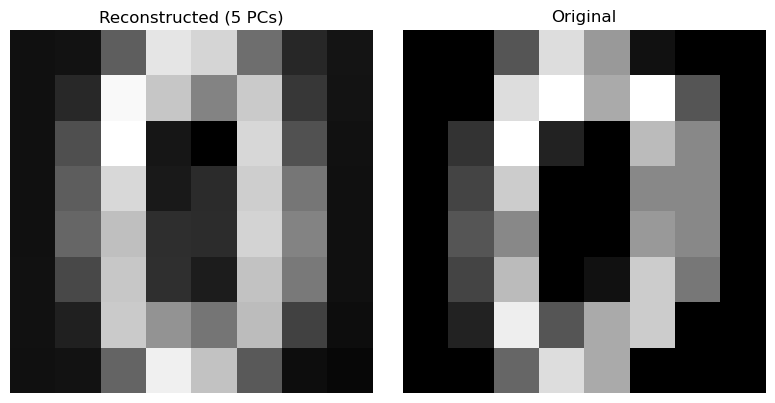

In [18]:
image_reconstructed = pca.inverse_transform(X_reduced[0].reshape(1,-1))
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(image_reconstructed.reshape((8,8)), cmap = 'gray')
plt.axis('off')
plt.title('Reconstructed (5 PCs)')
plt.subplot(1, 2, 2)
plt.imshow(X[0].reshape((8, 8)), cmap = 'gray')
plt.axis('off')
plt.title('Original')
plt.tight_layout()
plt.show()

We can also calculate the proportion of the total variance preserved by the first five principal components:

In [19]:
total_var = pca.explained_variance_ratio_.sum()
print(f'Proportion of total variance explained by the first {n_components} principal components: {total_var:.3f}')    

Proportion of total variance explained by the first 5 principal components: 0.545


It might be interesting to visualize the data in a lower-dimensional space. Let's reduce the dimensionality to three and plot the projected data. We will also color each data point according to the digit it represents. We will use `Plotly` to create an interactive plot.

Total variance explained: 40.3%


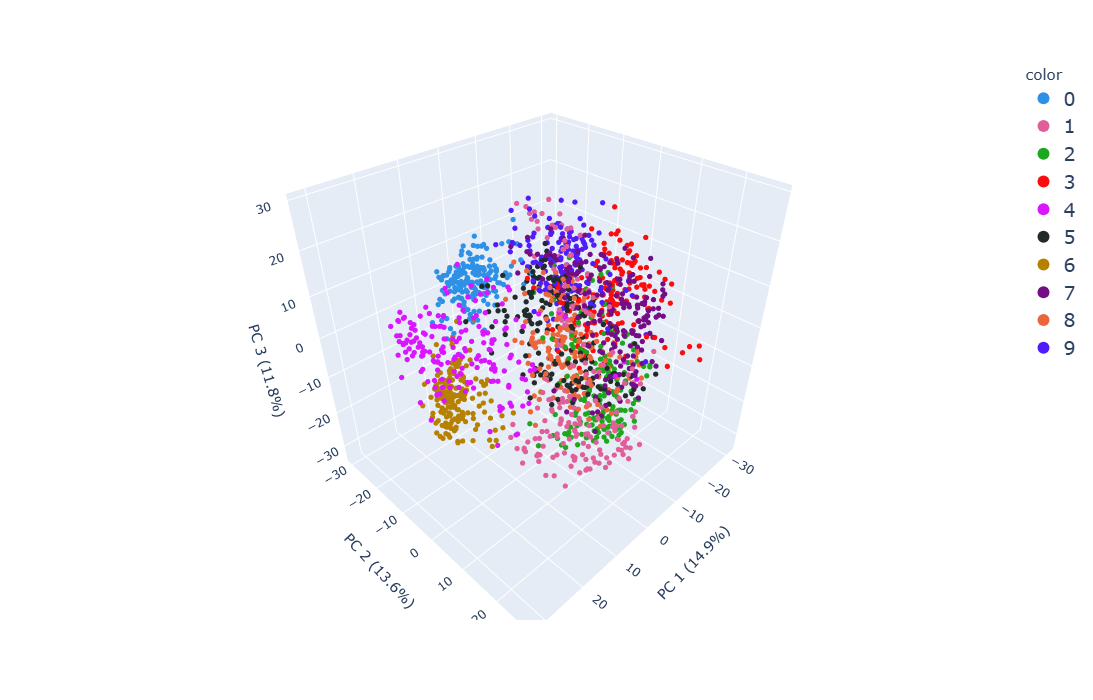

In [20]:
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)
variance = pca.explained_variance_ratio_ * 100
print(f'Total variance explained: {variance.sum():.1f}%')

fig = px.scatter_3d(
    x=X_reduced[:, 0], y=X_reduced[:, 1], z=X_reduced[:, 2],
    color=y.astype(str), color_discrete_sequence=px.colors.qualitative.Dark24)

fig.update_traces(marker_size=3)

fig.update_layout(
    width=700, height=700,
    scene=dict(xaxis_title=f'PC 1 ({variance[0]:.1f}%)',
        yaxis_title=f'PC 2 ({variance[1]:.1f}%)',
        zaxis_title=f'PC 3 ({variance[2]:.1f}%)'),
    legend=dict(itemsizing="constant", font=dict(size=19), title_font=dict(size=15)))

fig.show()

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 


**1.**
>Convert each of the given data matrices $X$ into mean-deviation form, then construct the sample covariance matrix. Assume that $X$ is written so that the rows represent features. <br><br>
>***a.*** $X= \begin{bmatrix} -3 & -1 &0 & 1 & 3 \\ -1 & -3 & 0 & 3 & 1 \end{bmatrix}$ <br><br>
>***b.*** $X=\begin{bmatrix} 0 & -1 & -4 & 3 & 2 \\ 6 & 6 & 6 & 6 & 6\end{bmatrix}$ <br><br>

**2.**
> Find the principal components of the data in Problem 1.

**3.**
> Let $x_1$ and $x_2$ be the variables for the data in Problem 1. Find a new variable $y_1$ of the form $y_1=c_1x_1+c_2x_2$ subject to $c_1^2+c_2^2=1$ such that $y_1$ has the maximum possible variance for the given data. How much of the total variance is explained by $y_1$?

**4.** 
>Use Python for this problem.<br>
>***a.*** Upload the dataset "Grades Set.csv" that contains exam scores for 25 students and create a data matrix $X$ consisting of all grades.<br>
>***b.*** Center the data and compute the sample covariance matrix. Be careful with the orientation of the matrix. Take the transpose of $X$ if needed.<br>
>***c.*** How much of the total variance of the data is explained by the first three principal components?<br>
>***d.*** If the data are reduced to three dimensions, how much of the total variance is lost?

**5.**
> In Problem 6 of Chapter 5.4, you were asked to perform a truncated SVD on the standardized dataset "Penguin map.csv". <br>
> ***a.*** Repeat the problem (parts a-d), but this time center the data without standardizing it. Compare the scatter plots from part d. <br>
> ***b.*** Use `PCA` to reduce the data to two dimensions. Plot a scatter plot of the reduced data and compare it with the scatter plot from part a. (Hint: If $X$ is the centered data matrix and $P_2$ is a matrix whose columns are the two unit eigenvectors corresponding to the first two principal components, then $Y=P_2^TX$ is the data matrix in the two-dimensional principal-component coordinate system.)<br>
> ***c.*** Discuss how and why the scatter plots differ when the data is standardized versus when it is only centered.